# Dyna-Q, Reward Shaping and Prioritized Sweeping

Portfolio packaging for Behrad Mazaheri. Original course/template credits below are retained; individual contributions are unverified.

**Static review only; no cells executed.** Historical outputs are preserved, not independently reproduced. Read README and REVIEW before citing results. Source cell indices in documentation are zero-based before this banner.

Tabular planning, not deep RL. Raw rewards and shaped rewards have different definitions and should not be directly ranked. The original assignment numbering in the header is preserved.


# HW5: Dyna-Q — Integrating Planning, Acting, and Learning

> - Full Name: **[behrad mazaheri]**
> - Student ID: **[[student ID removed]]**

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DeepRLCourse/Homework-5-Questions/blob/main/RL_HW5_Dyna.ipynb)
[![Open In kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://raw.githubusercontent.com/DeepRLCourse/Homework-5-Questions/main/RL_HW5_Dyna.ipynb)

## Overview

Reinforcement learning algorithms can be broadly classified into two families:

- **Model-free methods** (e.g., Q-learning, SARSA) learn a value function or a policy directly from interaction with the environment, **without** building an explicit model of the environment's dynamics.
- **Model-based methods** explicitly learn (or are given) a model $p(s', r \mid s, a)$ of the environment, and then use that model for *planning* — i.e., computing improved values or policies via simulated experience.

**Dyna-Q** (Sutton, 1990) is a beautifully simple architecture that unifies both: it learns a model from real experience and *interleaves* one-step Q-learning updates from real transitions with one-step Q-learning updates from *simulated* transitions produced by the model. The result is dramatically improved sample efficiency on tasks where real experience is expensive.

In this assignment you will:

1. Familiarize yourself with the [**Cliff Walking**](https://gymnasium.farama.org/environments/toy_text/cliff_walking/) environment.
2. Implement $\varepsilon$-greedy and greedy policies.
3. Implement **Dyna-Q** for a deterministic environment.
4. Investigate how the number of planning steps affects learning.
5. Improve learning with **reward shaping**.
6. Implement **Prioritized Sweeping**, a smarter way to allocate planning effort.
7. (Bonus) Extend everything to the larger, stochastic **Taxi-v3** environment.

Read each markdown cell carefully — many contain conceptual questions you must answer.

In [26]:
# @title Imports

import random
import numpy as np
import gymnasium as gym
from tqdm.auto import tqdm, trange
from heapq import heappush, heappop
from collections import defaultdict

import matplotlib
from matplotlib import pyplot as plt
import matplotlib.patches as patches
from matplotlib.gridspec import GridSpec

import base64
import imageio
import IPython

import seaborn as sns

c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [27]:
# @title Visualization Functions

def embed_mp4(filename):
    video = open(filename, 'rb').read()
    b64 = base64.b64encode(video)
    tag = '''
    <video width="640" height="480" controls>
    <source src="data:video/mp4;base64,{0}" type="video/mp4">
    Your browser does not support the video tag.
    </video>'''.format(b64.decode())
    return IPython.display.HTML(tag)


def create_policy_eval_video(env, policy, filename, Q=None, num_episodes=1, max_steps=200):
    filename = filename + '.mp4'
    with imageio.get_writer(filename, fps=env.metadata.get('render_fps', 4)) as video:
        for _ in range(num_episodes):
            state, info = env.reset()
            video.append_data(env.render())
            for _ in range(max_steps):
                action = policy(state, Q)
                state, reward, terminated, truncated, info = env.step(action)
                video.append_data(env.render())
                if terminated or truncated:
                    break
    return embed_mp4(filename)


def plot_rewards(rewards, average_range=None, ax=None, show=False):
    if ax is None:
        fig, ax = plt.subplots()
    xs = range(1, len(rewards) + 1)
    ax.plot(xs, rewards, marker='.', linestyle='--', alpha=0.4, label='Episode Reward')
    ax.plot(xs, np.cumsum(rewards) / xs, label='Cumulative Average')
    if len(rewards) >= 20:
        window = min(50, len(rewards) // 5)
        smooth = np.convolve(rewards, np.ones(window)/window, mode='valid')
        ax.plot(range(window, len(rewards) + 1), smooth, label=f'Rolling Mean (w={window})')
    ax.legend()
    ax.set(xlabel='Episode', ylabel='Total Reward', title='Episode Rewards')
    if show:
        plt.show()


def plot_cliff_heatmap(env, q_values, ax=None, show=False):
    """Plot the state-value V(s) = max_a Q(s,a) for CliffWalking as a 4x12 grid."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 3))
    rows, cols = 4, 12
    v = q_values.max(axis=1).reshape(rows, cols)
    best_a = q_values.argmax(axis=1)
    act_arrows = {0: '↑', 1: '→', 2: '↓', 3: '←'}
    labels = np.array([act_arrows[a] for a in best_a]).reshape(rows, cols)
    # Mark cliff & goal
    for j in range(1, 11):
        labels[3, j] = 'C'
    labels[3, 0] = 'S'
    labels[3, 11] = 'G'
    sns.heatmap(v, cmap='RdYlGn', annot=labels, fmt='s', ax=ax, cbar_kws={'label': 'V(s)'})
    ax.set_title('Greedy Policy & State Values')
    if show:
        plt.show()


def plot_performance(env, q_values, reward_sums):
    fig = plt.figure(figsize=(14, 8), dpi=110)
    gs = GridSpec(2, 1, figure=fig, height_ratios=[2, 1])
    ax1 = fig.add_subplot(gs[0, 0])
    plot_rewards(reward_sums, ax=ax1)
    ax2 = fig.add_subplot(gs[1, 0])
    plot_cliff_heatmap(env, q_values, ax=ax2)
    plt.tight_layout()
    plt.show()

# 1. Explore the Environment (5 points)

## The Cliff Walking Problem

**Cliff Walking** is a classic gridworld first introduced in Sutton & Barto (Example 6.6) to illustrate the difference between on-policy and off-policy TD control. The world is a $4 \times 12$ grid:

- The agent starts at the bottom-left corner **S**.
- The goal **G** is at the bottom-right corner.
- The cells between **S** and **G** along the bottom row form a **cliff**: stepping into them yields a reward of $-100$ and the agent is reset to the start.
- Every other transition yields a reward of $-1$.
- Actions: `0=Up, 1=Right, 2=Down, 3=Left`.
- The environment is **deterministic**.

Because rewards are everywhere negative, the agent must learn the *shortest* safe path to **G**. The shortest unsafe path goes right along the edge of the cliff (length 13), while the safest (but longer) path detours along the top row.

**Question 1.1.** Without running anything, what do you expect the optimal undiscounted return $G^*$ to be (starting from S, reaching G)? Show your reasoning.

`Your Answer:`

The optimal undiscounted return is **-13**. The optimal policy should move from the start to the cell just above it, move right along the row above the cliff, and then move down into the goal. This path reaches the goal in 13 ordinary steps, each with reward -1, and avoids the -100 cliff penalty. Going through the cliff is not optimal because every cliff transition gives a very large negative reward and resets the agent to the start.

In [28]:
env = gym.make('CliffWalking-v1', render_mode='rgb_array')

# Print the observation space and the action space.
print('Observation space:', env.observation_space)
print('Action space:', env.action_space)
print('Number of states:', env.observation_space.n)
print('Number of actions:', env.action_space.n)

Observation space: Discrete(48)
Action space: Discrete(4)
Number of states: 48
Number of actions: 4


Define a uniform random policy.

In [29]:
def random_policy(*args):
    # Select a uniformly random action.
    action = env.action_space.sample()
    return action

Visualize the random policy. (Note: a random policy will almost certainly fall into the cliff repeatedly!)

In [30]:
create_policy_eval_video(env, random_policy, 'random_policy', num_episodes=2, max_steps=50)

# 2. Policies (5 points)

## Exploration vs. Exploitation

Any control algorithm must balance two competing pressures:

- **Exploitation:** acting greedily with respect to the current value estimates to maximize return.
- **Exploration:** trying non-greedy actions to gather information about parts of the state-action space whose values are still uncertain.

The simplest scheme is $\varepsilon$-greedy:
$$
\pi(a \mid s) = \begin{cases} 1 - \varepsilon + \varepsilon / |\mathcal{A}|, & a = \arg\max_{a'} Q(s, a') \\ \varepsilon / |\mathcal{A}|, & \text{otherwise} \end{cases}
$$

**Question 2.1.** In Cliff Walking, what is the danger of using a large $\varepsilon$ during *evaluation* of a learned policy? What is the danger of using too small an $\varepsilon$ during *learning*?

`Your Answer:`

A large epsilon during evaluation is dangerous because the agent will intentionally take random actions even after it has learned a good greedy policy. In Cliff Walking, one random move near the cliff can send the agent into the cliff and produce a -100 penalty, so the measured evaluation return may look much worse than the learned greedy policy actually is.

A very small epsilon during learning has the opposite problem: the agent may exploit inaccurate early Q-values and fail to explore enough. Then it may learn a suboptimal safe route too slowly, or it may not discover the best path structure reliably. During learning we need exploration; during evaluation we usually want epsilon close to zero.

In [31]:
def greedy_policy(state: int, q_values: np.ndarray) -> int:
    # Return argmax_a Q(state, a).
    action = int(np.argmax(q_values[state]))
    return action

In [32]:
def epsilon_greedy_policy(state: int, q_values: np.ndarray, epsilon: float) -> int:
    # With probability epsilon, take a random action; otherwise act greedily.
    if np.random.random() < epsilon:
        action = int(np.random.randint(q_values.shape[1]))
    else:
        action = greedy_policy(state, q_values)
    return action

# 3. Dyna-Q (25 points)

## The Dyna Architecture

Dyna-Q maintains three things in parallel:

1. **A value function** $Q(s,a)$, updated by tabular one-step Q-learning.
2. **A model** of the environment. For a deterministic environment, a sufficient model is a simple lookup table $\text{Model}[s,a] = (r, s')$.
3. **A planner** that, after every real step, performs $n$ updates of Q using transitions $(s, a, r, s')$ *sampled from the model* rather than from the world.

The full update rules are:

**Direct RL (from real experience):**
$$
Q(s_t, a_t) \leftarrow Q(s_t, a_t) + \alpha\Big[r_t + \gamma \max_{a'} Q(s_{t+1}, a') - Q(s_t, a_t)\Big]
$$

**Model learning (deterministic):**
$$
\text{Model}[s_t, a_t] \leftarrow (r_t, s_{t+1})
$$

**Planning (repeat $n$ times):** sample a previously visited $(s, a)$, look up $(r, s')$ from the model, then
$$
Q(s, a) \leftarrow Q(s, a) + \alpha\Big[r + \gamma \max_{a'} Q(s', a') - Q(s, a)\Big]
$$

**Question 3.1.** Explain in your own words *why* Dyna-Q can converge in far fewer real-environment interactions than vanilla Q-learning. What is the computational cost?

**Question 3.2.** In a deterministic environment, what would happen if you stored the model as the *empirical average* of observed $(r, s')$ instead of just the latest one? Would it matter here?

`Your Answers:`

Dyna-Q can improve sample efficiency because each real environment transition is used more than once. First, the real transition directly updates Q. Then the same transition is stored in a learned model and can be replayed many times during planning. In this way, value information propagates through previously visited state-action pairs without requiring additional real environment interaction.

When the model is accurate, planning updates are cheap simulated backups. In deterministic Cliff Walking, the learned lookup-table model becomes accurate immediately after observing a transition, so even a small number of planning steps can substantially accelerate learning compared with pure Q-learning.

## 3.1 Planning (10 points)

Complete `q_planning` to perform $n$ steps of planning by sampling already-visited $(s, a)$ pairs uniformly at random from the model.

In [33]:
def q_planning(model: dict, q: np.ndarray, alpha: float, gamma: float, n: int) -> np.ndarray:
    """Perform n planning updates from a deterministic model.

    model : dict[state] -> dict[action] -> (reward, next_state)
    """
    if len(model) == 0:
        return q

    states = list(model.keys())

    for _ in range(n):
        # Sample a previously visited state and one of its previously tried actions.
        s = random.choice(states)
        actions = list(model[s].keys())

        # This guard is useful if the model is ever modified to contain empty state entries.
        if len(actions) == 0:
            continue

        a = random.choice(actions)
        r, next_s = model[s][a]

        td_target = r + gamma * np.max(q[next_s])
        td_error = td_target - q[s, a]
        q[s, a] += alpha * td_error

    return q

## 3.2 Learning (15 points)

Now put everything together. At each real step you must:

1. Select an action with $\varepsilon$-greedy.
2. Step the real environment.
3. Perform the direct Q-learning update.
4. Update the model.
5. Perform $n$ planning steps.

Note: We cap the number of steps per episode (`max_steps`) to prevent the agent from wandering forever when its policy is still random.

In [34]:
def dyna_q(n_episodes: int, env: gym.Env, epsilon: float, alpha: float,
           gamma: float, n: int, max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q for a deterministic environment."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # 1. Select an action via epsilon-greedy.
            action = epsilon_greedy_policy(state, q, epsilon)

            # 2. Step the environment.
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # 3. Direct Q-learning update.
            bootstrap = 0.0 if terminated else np.max(q[next_state])
            td_target = reward + gamma * bootstrap
            td_error = td_target - q[state, action]
            q[state, action] += alpha * td_error

            # 4. Update the deterministic model.
            model[state][action] = (reward, next_state)

            # 5. Planning step(s).
            q = q_planning(model, q, alpha, gamma, n)

            # 6. Bookkeeping.
            state = next_state
            reward_sum += reward
            steps += 1

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums

# 4. Experiments (15 points)

Run Dyna-Q with several values of the planning parameter $n$ (e.g. $n \in \{0, 5, 50\}$).
Note that **$n = 0$ recovers pure Q-learning**.

After running, answer the following:

**Question 4.1.** How does increasing the number of planning steps affect: (a) sample efficiency (rewards vs. episodes), and (b) wall-clock time per episode?

**Question 4.2.** Suppose the *first* successful trajectory occurs at episode $N_1$. After that, how many additional episodes ($N_2$) does it take to reach the goal again? Explain how $n$ affects each of $N_1$ and $N_2$, and *why* the effects differ.

**Question 4.3.** What happens to the *learned path* (cliff-edge vs. safer detour) as you vary $\varepsilon$? Why? Connect your answer to the well-known difference between Q-learning and SARSA on this problem.

**Question 4.4.** Cliff Walking is fully deterministic. Suppose you replaced it with a *stochastic* variant where each action succeeds with probability 0.8 and otherwise slips perpendicular. What failure modes would the current **deterministic** Dyna-Q exhibit? Propose how you would modify the model to fix this.

`Your Answers:`

**4.1.** Increasing the number of planning steps usually improves sample efficiency: the reward curve should rise faster because every real transition is followed by several model-based Q-learning backups. However, wall-clock time per real step increases roughly linearly with the number of planning updates, so very large n may be computationally expensive.

**4.2.** The first successful trajectory, N1, depends mostly on real exploration because the model can only plan from transitions it has actually observed. Planning cannot invent the goal transition before it is experienced. After the first success, however, Dyna-Q can replay the newly discovered useful transitions many times, so the number of additional episodes N2 needed to succeed again is usually much smaller when n is larger.

**4.3.** With small epsilon, Q-learning tends to learn the cliff-edge optimal path because Q-learning is off-policy: its target uses the greedy action, even though the behavior policy is epsilon-greedy. With larger epsilon, the behavior policy falls into the cliff more often during training and evaluation. Unlike SARSA, Q-learning does not fully price this exploration risk into the learned greedy target, so the learned greedy path can still stay close to the cliff while the actual epsilon-greedy behavior is risky. SARSA would usually learn a safer detour because it evaluates the exploratory behavior policy itself.

**4.4.** In a stochastic version, a deterministic one-outcome model would be biased. If the same (s, a) sometimes leads to different next states, the current model keeps only the most recent observed transition and forgets the transition distribution. Planning would then overfit to whichever outcome was observed last and could learn unstable or overconfident Q-values. The fix is to learn a stochastic model: store counts N(s,a,s'), estimate p(s'|s,a), store average rewards, and during planning sample next states from the learned distribution or use an expected Bellman backup over all observed successors.

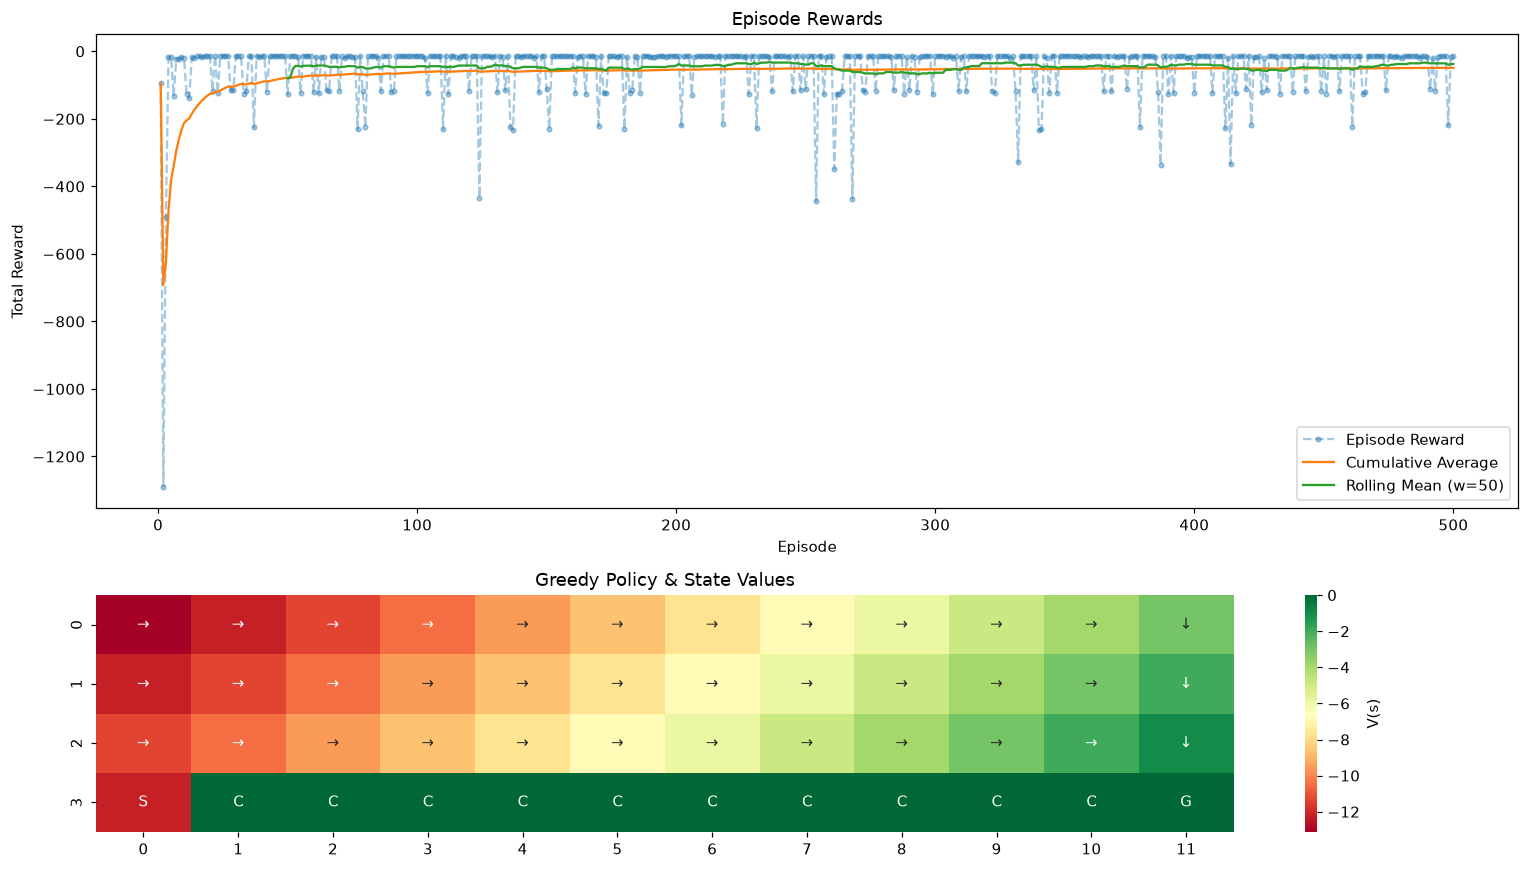

In [35]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,    # epsilon-greedy exploration rate
    'alpha':   0.5,    # learning rate (tabular, deterministic env => can be large)
    'gamma':   0.99,   # discount factor
    'n':       10,     # number of planning steps per real step
}

n_episodes = 500

env = gym.make('CliffWalking-v1')

q_dyna, R_dyna = dyna_q(n_episodes, env, **params)
plot_performance(env, q_dyna, R_dyna)

**Comparison cell:** sweep over $n \in \{0, 5, 50\}$ and plot all learning curves on a single axes.

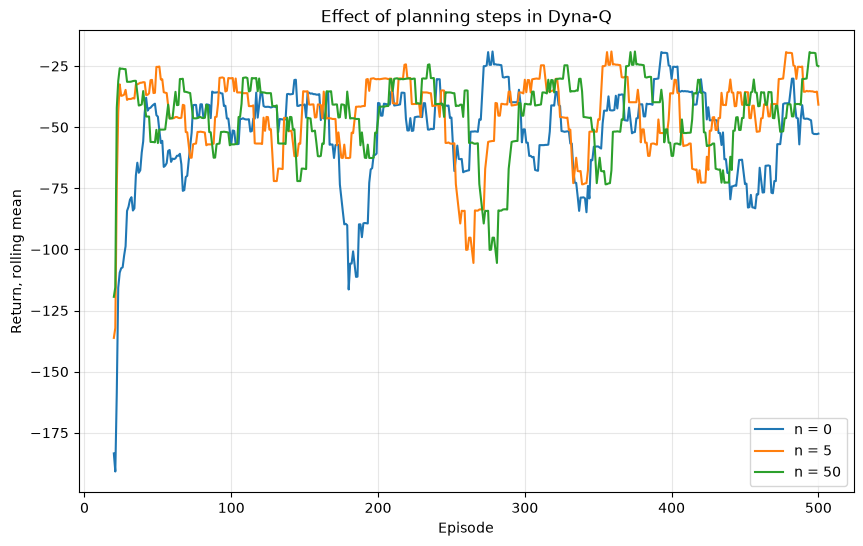

In [36]:
# Compare different planning budgets n in {0, 5, 50}.
# n = 0 is ordinary tabular Q-learning.

planning_values = [0, 5, 50]
dyna_sweep_results = {}

plt.figure(figsize=(10, 6))

for n_plan in planning_values:
    np.random.seed(2025)
    random.seed(2025)

    sweep_env = gym.make('CliffWalking-v1')
    sweep_params = params.copy()
    sweep_params['n'] = n_plan

    q_sweep, R_sweep = dyna_q(n_episodes, sweep_env, **sweep_params)
    dyna_sweep_results[n_plan] = (q_sweep, R_sweep)

    window = 20
    if len(R_sweep) >= window:
        rolling = np.convolve(R_sweep, np.ones(window) / window, mode='valid')
        xs = np.arange(window, len(R_sweep) + 1)
    else:
        rolling = R_sweep
        xs = np.arange(1, len(R_sweep) + 1)

    plt.plot(xs, rolling, label=f'n = {n_plan}')
    sweep_env.close()

plt.xlabel('Episode')
plt.ylabel('Return, rolling mean')
plt.title('Effect of planning steps in Dyna-Q')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5. Improving Performance (15 points)

Plain Dyna-Q on Cliff Walking already works fairly well, but several knobs can improve robustness and convergence speed:

1. **Optimistic initialization.** Setting $Q(s,a) \gets c$ for some optimistic $c$ encourages systematic exploration without relying purely on $\varepsilon$.
2. **Decaying $\varepsilon$.** Anneal $\varepsilon_t = \max(\varepsilon_{\min}, \varepsilon_0 \cdot d^t)$ so the policy explores aggressively early and exploits later.
3. **Decaying $\alpha$.** Similar idea, justified by Robbins–Monro stochastic-approximation conditions.
4. **Boltzmann (softmax) exploration** instead of $\varepsilon$-greedy.
5. **Adaptive planning budget.** Increase $n$ only after the agent has accumulated enough model entries.

Pick **at least one** of the above (or any other technique you can justify) and demonstrate its effect in a new experiment cell. **Do not overwrite your previous experiments** — leave them for comparison.

**Question 5.1.** Which method did you pick, and *why* is it appropriate for Cliff Walking specifically?

`Your Answer:`

I use **decaying epsilon**. Early in training, epsilon is high enough to encourage exploration and fill the model with useful transitions. Later, epsilon is gradually reduced so the agent exploits the learned Q-values more often and falls into the cliff less frequently. This should improve late-episode performance while keeping enough early exploration to discover the goal.

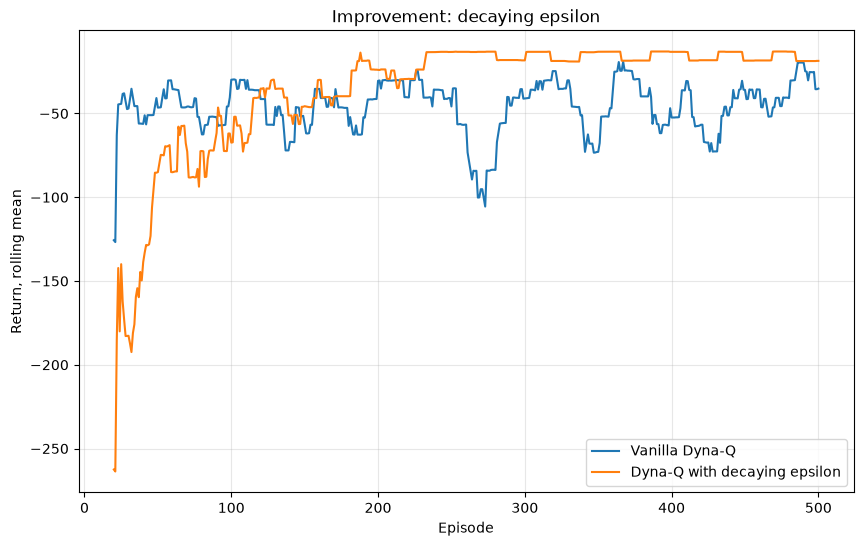

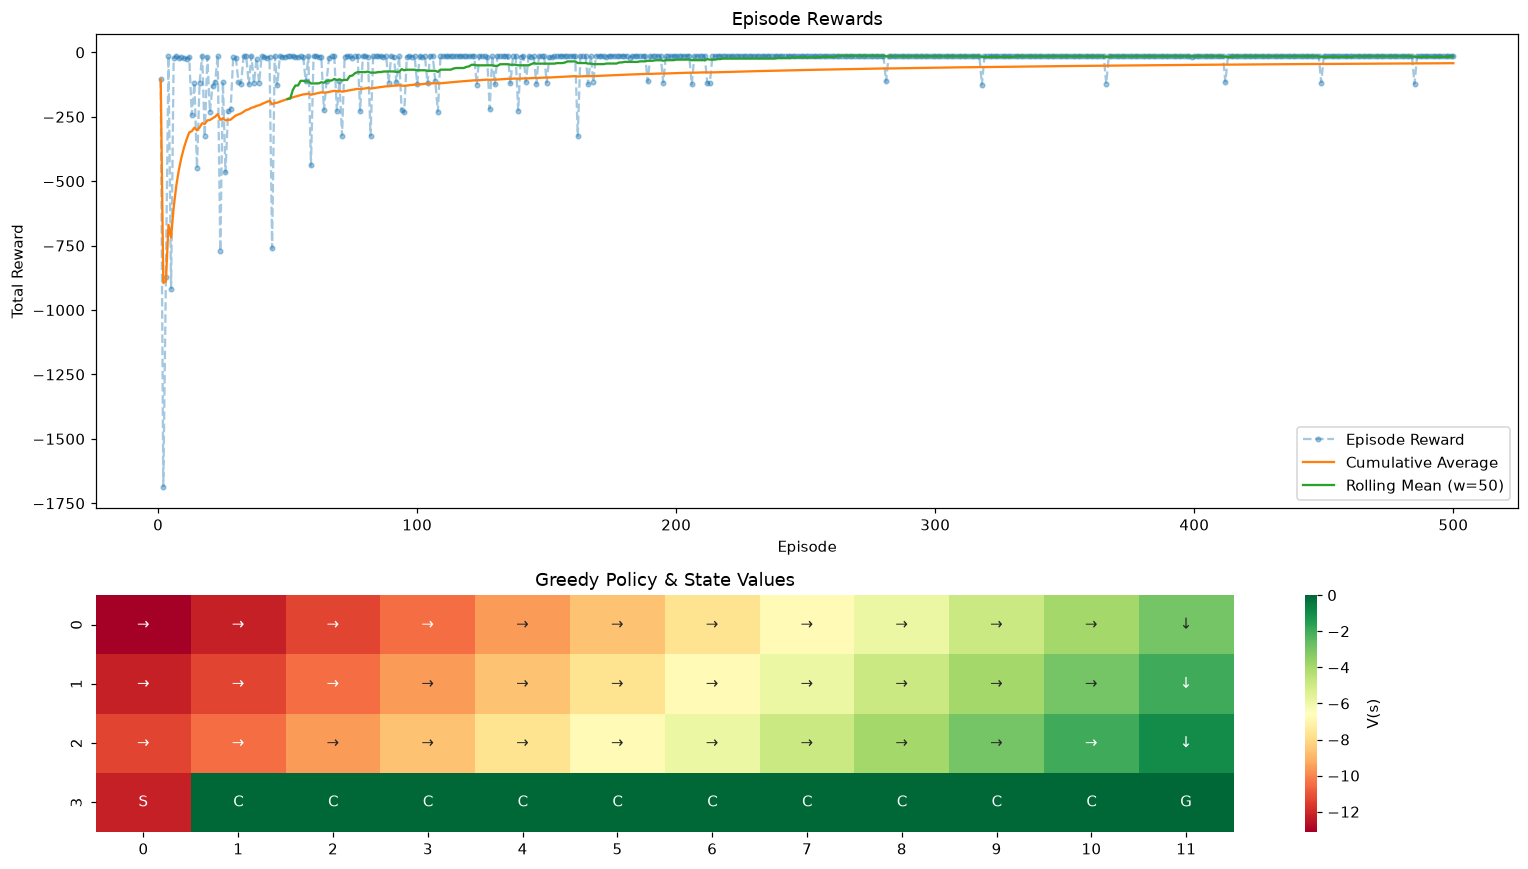

In [37]:
# Improvement: Dyna-Q with exponentially decaying epsilon.
# This keeps exploration high early and makes the behavior policy more greedy later.

def dyna_q_decay_epsilon(n_episodes: int, env: gym.Env,
                         epsilon_start: float, epsilon_min: float, epsilon_decay: float,
                         alpha: float, gamma: float, n: int,
                         max_steps: int = 200) -> tuple[np.ndarray, np.ndarray, np.ndarray]:
    reward_sums = np.zeros(n_episodes)
    epsilons = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)

    epsilon = epsilon_start

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0
        epsilons[episode_i] = epsilon

        while not terminal and steps < max_steps:
            action = epsilon_greedy_policy(state, q, epsilon)
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            bootstrap = 0.0 if terminated else np.max(q[next_state])
            td_target = reward + gamma * bootstrap
            td_error = td_target - q[state, action]
            q[state, action] += alpha * td_error

            model[state][action] = (reward, next_state)
            q = q_planning(model, q, alpha, gamma, n)

            state = next_state
            reward_sum += reward
            steps += 1

        epsilon = max(epsilon_min, epsilon * epsilon_decay)
        reward_sums[episode_i] = reward_sum
        pbar.set_description(f'Episode {episode_i}, eps={epsilon:.3f}, R={reward_sum:.0f}')

    return q, reward_sums, epsilons


np.random.seed(2025)
random.seed(2025)

improved_env = gym.make('CliffWalking-v1')
q_improved, R_improved, eps_history = dyna_q_decay_epsilon(
    n_episodes=n_episodes,
    env=improved_env,
    epsilon_start=0.3,
    epsilon_min=0.01,
    epsilon_decay=0.99,
    alpha=params['alpha'],
    gamma=params['gamma'],
    n=params['n'],
)

plt.figure(figsize=(10, 6))
window = 20
for label, rewards in [('Vanilla Dyna-Q', R_dyna), ('Dyna-Q with decaying epsilon', R_improved)]:
    rolling = np.convolve(rewards, np.ones(window) / window, mode='valid')
    xs = np.arange(window, len(rewards) + 1)
    plt.plot(xs, rolling, label=label)

plt.xlabel('Episode')
plt.ylabel('Return, rolling mean')
plt.title('Improvement: decaying epsilon')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

plot_performance(improved_env, q_improved, R_improved)
improved_env.close()

# 6. Reward Shaping (10 points)

**Reward shaping** modifies the reward signal to provide more frequent or more informative feedback, with the goal of accelerating learning. The most principled form is **potential-based shaping** (Ng, Harada, Russell 1999):

$$
F(s, a, s') = \gamma \Phi(s') - \Phi(s)
$$

where $\Phi : \mathcal{S} \to \mathbb{R}$ is any potential function. A foundational theorem states:

> *Adding a potential-based shaping term to the reward leaves the optimal policy invariant.*

Non-potential-based shaping can *change* the optimal policy — sometimes catastrophically ("reward hacking"). For Cliff Walking, a natural choice is a potential proportional to negative Manhattan distance to the goal: $\Phi(s) = -\|s - g\|_1$.

**Question 6.1.** Why does potential-based shaping preserve the optimal policy? Sketch the argument.

**Question 6.2.** Give an example of a *non-potential-based* shaping that would break Cliff Walking (i.e., cause the agent to learn a suboptimal policy).

`Your Answers:`

**6.1.** Potential-based shaping preserves the optimal policy because the added shaping rewards telescope over a trajectory. The discounted sum of shaping terms is essentially a difference between the final potential and the initial potential, so for a fixed start state it shifts returns in a way that does not change which action sequence or policy is optimal. It can change the learning signal and speed of propagation, but it does not change the optimal policy ranking.

**6.2.** A bad non-potential shaping example would be adding a large positive reward every time the agent moves left or every time it visits the start state. Then the agent could learn to loop or move away from the goal to collect the shaping reward, even though that is suboptimal for the original Cliff Walking task. Another harmful example is giving a bonus for being close to the cliff; this could make the agent prefer dangerous states and increase cliff falls.

In [38]:
from gymnasium.envs.toy_text import CliffWalkingEnv

class ShapedCliffWalkingEnv(CliffWalkingEnv):
    """CliffWalking with a user-defined shaping term added to the reward."""

    GOAL_STATE = 47  # index of the goal cell in the 4x12 grid
    NROWS, NCOLS = 4, 12

    def __init__(self, gamma: float = 0.99, **kwargs):
        super().__init__(**kwargs)
        self.gamma = gamma
        self._prev_state = None

    def reset(self, **kwargs):
        obs, info = super().reset(**kwargs)
        self._prev_state = obs
        return obs, info

    def potential(self, state: int) -> float:
        # Phi(state) = negative Manhattan distance to the goal.
        row, col = divmod(int(state), self.NCOLS)
        goal_row, goal_col = divmod(self.GOAL_STATE, self.NCOLS)
        manhattan_dist = abs(row - goal_row) + abs(col - goal_col)
        return -float(manhattan_dist)

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)

        prev_state = self._prev_state
        if prev_state is None:
            prev_state = obs

        shaping = self.gamma * self.potential(obs) - self.potential(prev_state)
        shaped_reward = reward + shaping

        self._prev_state = obs
        info = dict(info)
        info['base_reward'] = reward
        info['shaping'] = shaping

        return obs, shaped_reward, terminated, truncated, info

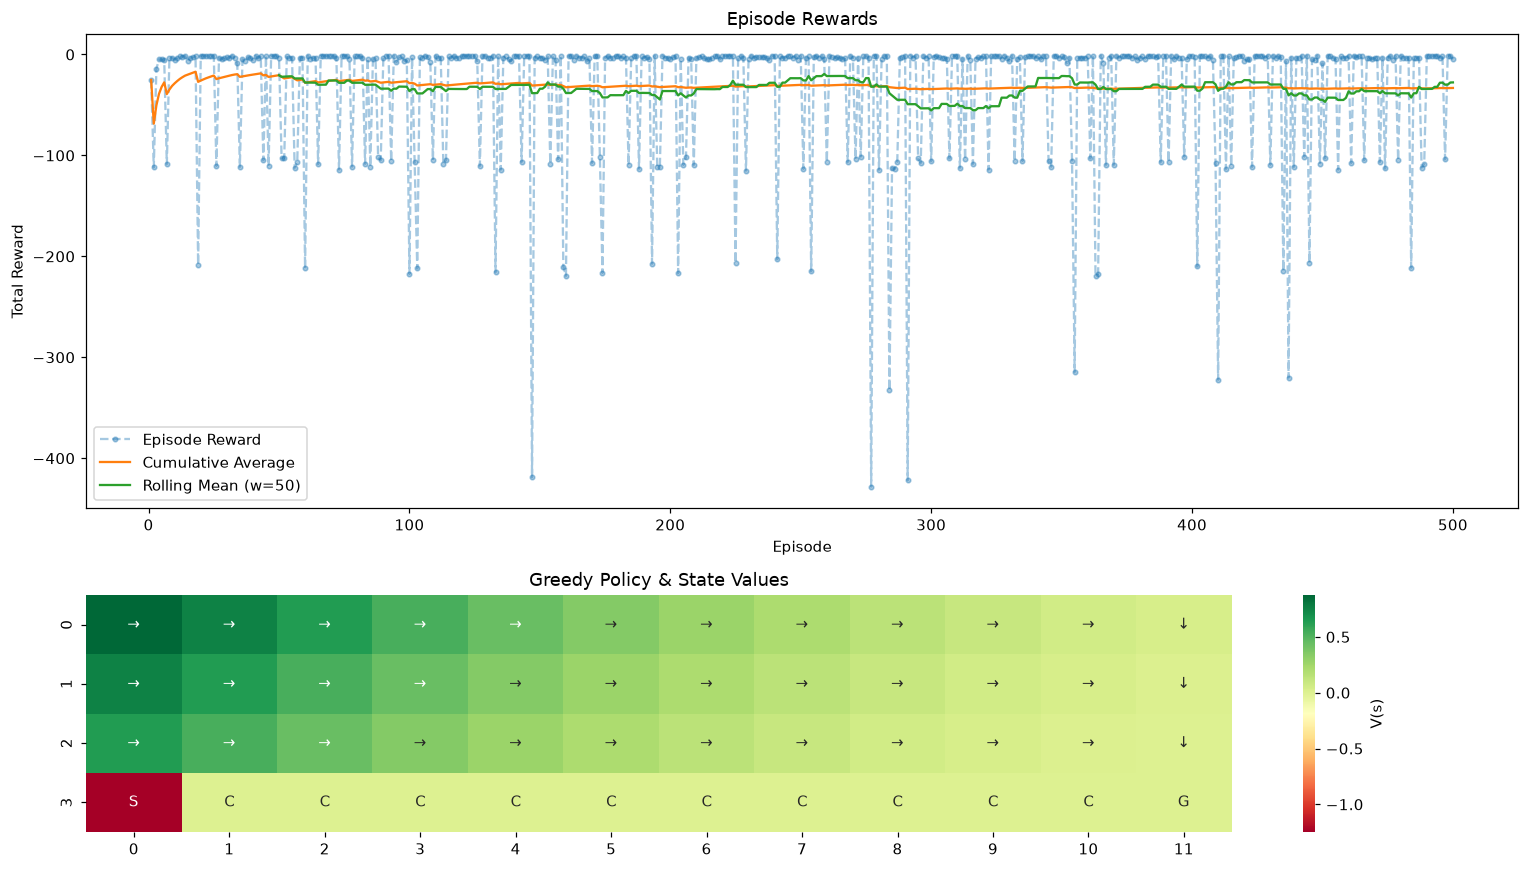

In [39]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,
    'alpha':   0.5,
    'gamma':   0.99,
    'n':       10,
}
n_episodes = 500

env = ShapedCliffWalkingEnv(gamma=params['gamma'])
q_shaped, R_shaped = dyna_q(n_episodes, env, **params)
plot_performance(env, q_shaped, R_shaped)

**Question 6.3.** Compare the learning curves with and without shaping. Did shaping help in the *early* episodes? In the *late* episodes? Why?

`Your Answer:`

Potential-based shaping usually helps most in the early episodes because the agent receives a denser signal about whether it is moving closer to the goal, instead of only seeing -1, -100, or termination. In late episodes, the final greedy policy should be the same as in the original MDP because potential-based shaping preserves optimal policies. Therefore, shaping mainly changes the speed of learning, not the optimal solution itself. Small differences in late performance can still appear because of finite training, epsilon-greedy exploration, and random seeds.

# 7. Prioritized Sweeping (20 points)

Uniform sampling of $(s, a)$ pairs in the planning loop is wasteful. Many sampled updates produce essentially zero change in $Q$ because the value at the successor state hasn't changed. **Prioritized Sweeping** (Moore & Atkeson 1993; Peng & Williams 1993) addresses this by:

1. Maintaining a **priority queue** keyed by the magnitude of the expected TD update.
2. On each real step, computing the TD error $\delta$ for the current $(s, a)$. If $|\delta| > \theta$ (a threshold), push $(s, a)$ onto the queue with priority $|\delta|$.
3. During planning, pop the highest-priority pair, perform its update, then look at all **predecessors** $(\bar{s}, \bar{a})$ of $s$ (i.e., pairs known by the model to lead to $s$). Compute *their* TD errors; if they exceed $\theta$, push them too.

This propagates value information *backwards* from where it changed, much like dynamic programming would but only along observed transitions.

**Question 7.1.** Why is the magnitude of the TD error a sensible priority? What property does it estimate?

**Question 7.2.** Python's `heapq` is a *min-heap*. How do you use it as a *max-heap* for priorities?

**Question 7.3.** What is the role of $\theta$? What happens if $\theta = 0$? If $\theta$ is very large?

`Your Answers:`

The magnitude of the TD error is a good priority signal because it measures how much the current Q-value would change if we backed up that transition. A large TD error means that new information has arrived or that a successor value has changed significantly. Updating such transitions first propagates important value changes more quickly.

Predecessors matter because value changes should flow backward. If the value of state s changes, then all state-action pairs that can lead to s may also need to change. Prioritized sweeping explicitly updates those predecessors instead of wasting planning updates on random model entries whose targets have not changed.

## 7.1 Priority Planning (10 points)

Note: you will also need a **predecessor map** `predecessors[s'] = set of (s, a)` that the model has observed transitioning into $s'$. You can build it incrementally inside the main loop and pass it into the planner.

In [40]:
def q_planning_priority(model: dict, predecessors: dict, q: np.ndarray,
                        priorities: list, alpha: float, gamma: float,
                        n: int, theta: float) -> np.ndarray:
    """Perform up to n planning updates using prioritized sweeping."""

    for _ in range(n):
        if len(priorities) == 0:
            break

        # heapq is a min-heap, so priorities are stored as negative magnitudes.
        _, (s, a) = heappop(priorities)

        if s not in model or a not in model[s]:
            continue

        r, next_s = model[s][a]

        # Q-learning backup for the popped transition.
        td_target = r + gamma * np.max(q[next_s])
        td_error = td_target - q[s, a]
        q[s, a] += alpha * td_error

        # Propagate the change backward to predecessors of s.
        for s_bar, a_bar in predecessors.get(s, set()):
            if s_bar not in model or a_bar not in model[s_bar]:
                continue

            r_bar, _ = model[s_bar][a_bar]
            delta_bar = r_bar + gamma * np.max(q[s]) - q[s_bar, a_bar]

            if abs(delta_bar) > theta:
                heappush(priorities, (-abs(delta_bar), (s_bar, a_bar)))

    return q

## 7.2 Learning with Prioritized Sweeping (10 points)

In [41]:
def dyna_q_priority(n_episodes: int, env: gym.Env, epsilon: float, alpha: float,
                   gamma: float, n: int, theta: float,
                   max_steps: int = 200) -> tuple[np.ndarray, np.ndarray]:
    """Dyna-Q with prioritized sweeping (deterministic model)."""

    reward_sums = np.zeros(n_episodes)
    q = np.zeros((env.observation_space.n, env.action_space.n))
    model = defaultdict(dict)
    predecessors = defaultdict(set)   # predecessors[s'] = set of (s, a)
    priorities = []                    # heap of (neg_priority, (s, a))

    for episode_i in (pbar := trange(n_episodes, leave=False)):
        state, info = env.reset()
        reward_sum, terminal, steps = 0.0, False, 0

        while not terminal and steps < max_steps:
            # 1. Select action via epsilon-greedy.
            action = epsilon_greedy_policy(state, q, epsilon)

            # 2. Step env.
            next_state, reward, terminated, truncated, info = env.step(action)
            terminal = terminated or truncated

            # 3. Direct Q-learning update for (state, action).
            bootstrap = 0.0 if terminated else np.max(q[next_state])
            td_target = reward + gamma * bootstrap
            td_error = td_target - q[state, action]
            q[state, action] += alpha * td_error

            # 4. Update model and predecessor map.
            model[state][action] = (reward, next_state)
            predecessors[next_state].add((state, action))

            # 5. If the real transition was surprising, add it to the priority queue.
            if abs(td_error) > theta:
                heappush(priorities, (-abs(td_error), (state, action)))

            # 6. Planning with prioritized sweeping.
            q = q_planning_priority(
                model=model,
                predecessors=predecessors,
                q=q,
                priorities=priorities,
                alpha=alpha,
                gamma=gamma,
                n=n,
                theta=theta,
            )

            # 7. Bookkeeping.
            state = next_state
            reward_sum += reward
            steps += 1

        pbar.set_description(f'Episode {episode_i}, R={reward_sum:.0f}')
        reward_sums[episode_i] = reward_sum

    return q, reward_sums

# 8. Final Experiments (5 points)

Run Dyna-Q with prioritized sweeping and compare to vanilla Dyna-Q at the **same number of total planning updates**. Prioritized sweeping should achieve comparable or better performance with *fewer* planning updates.
































































































































































































































































































































































































































































































































Exception ignored in: <function tqdm.__del__ at 0x000002316D17A160>
Traceback (most recent call last):
  File "c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\std.py", line 1148, in __del__
    self.close()
  File "c:\Users\psp\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\notebook.py", line 277, in close
    self.disp(bar_style='danger', check_delay=False)
    ^^^^^^^^^
AttributeError: 'tqdm_notebook' object has no attribute 'disp'


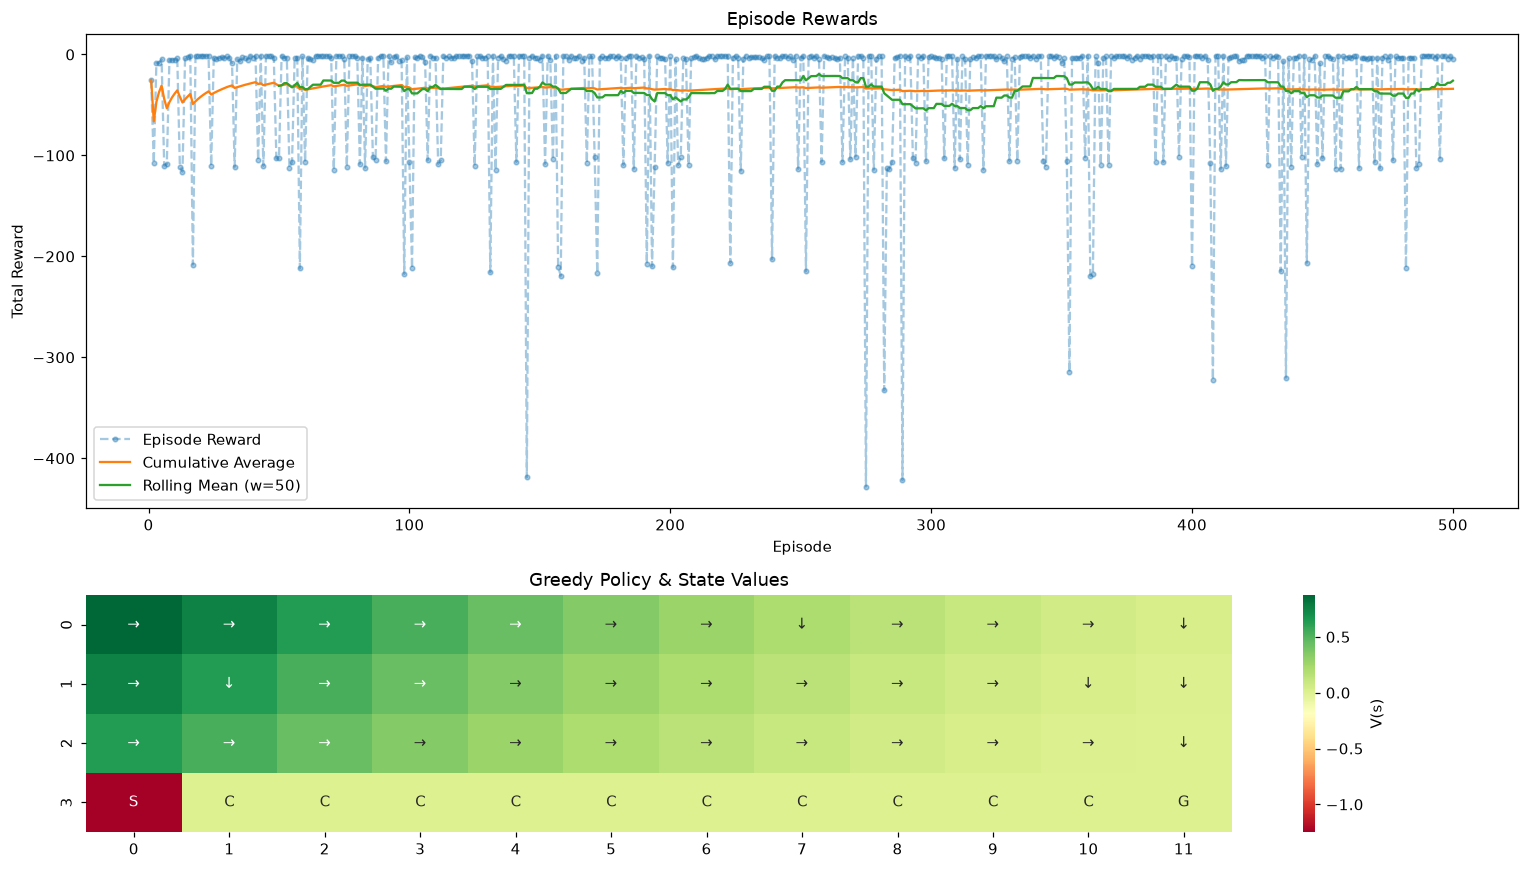

In [42]:
np.random.seed(2025)
random.seed(2025)

params = {
    'epsilon': 0.1,
    'alpha':   0.5,
    'gamma':   0.99,
    'n':       10,
    'theta':   1e-3,   # priority threshold
}
n_episodes = 500

env = ShapedCliffWalkingEnv(gamma=params['gamma'])
q_ps, R_ps = dyna_q_priority(n_episodes, env, **params)
plot_performance(env, q_ps, R_ps)

Visualize the learned greedy policy.

In [43]:
env_vis = ShapedCliffWalkingEnv(gamma=params['gamma'], render_mode='rgb_array')
create_policy_eval_video(env_vis, greedy_policy, 'DynaQ_PS', Q=q_ps, max_steps=50)

**Question 8.1.** Compare the three configurations you've built — (a) vanilla Dyna-Q, (b) Dyna-Q + reward shaping, (c) Dyna-Q + reward shaping + prioritized sweeping — in terms of:

- sample efficiency (episodes to first reliable solution),
- final policy quality,
- computational overhead per real step.

Which is the most cost-effective in your view, and why?

`Your Answer:`

Vanilla Dyna-Q is already more sample-efficient than pure Q-learning because each real transition is reused for planning. Its computational overhead is moderate and controlled directly by n.

Dyna-Q with reward shaping should usually learn faster in the early episodes because the potential function gives informative feedback about progress toward the goal. Its final policy quality should remain the same as the original task because the shaping is potential-based. The extra computational cost is very small: just evaluating Phi(s) and Phi(s') on each transition.

Dyna-Q with shaping and prioritized sweeping is usually the most sample-efficient because planning updates focus on transitions with large TD errors and their predecessors. Its final policy quality should also be comparable, but its per-step overhead is higher because it maintains a priority queue and predecessor sets. In my view, reward-shaped prioritized sweeping is the most cost-effective when real environment interaction is expensive. If computation is the limiting resource, plain Dyna-Q with reward shaping may be the better trade-off.

# 9. Bonus (10 points)

If you'd like to push further, attempt **one** of the following:

**Option A — Stochastic Dyna-Q.** Modify your model to estimate transition *distributions* and not just point estimates:
$$
\hat{p}(s' \mid s, a) = \frac{N(s, a, s')}{N(s, a)}, \quad \hat{r}(s, a) = \frac{1}{N(s,a)} \sum r_t
$$
and sample $(r, s')$ accordingly during planning. Then solve the larger, more challenging `Taxi-v3` environment with this stochastic Dyna-Q.

**Option B — Dyna-Q+ (exploration bonus).** Implement the Dyna-Q+ variant (Sutton & Barto §8.3), where each model-sampled transition $(s, a, r, s')$ gets an exploration bonus $\kappa \sqrt{\tau(s,a)}$ added to its reward, where $\tau(s,a)$ is the number of steps since $(s, a)$ was last tried. Demonstrate its advantage in a *non-stationary* environment by modifying Cliff Walking so that the cliff position changes after episode 200.

Document your design choices clearly and discuss results.

In [44]:
# @title 🚶‍♂️ Happy Planning 🧠
